# E11 · Onset versus continuation

Protocol addendum: [`protocolo_revision.md`](../protocolo_revision.md). Written after E1–E8, in response to external feedback; every result here is exploratory. Negative changes favour the first arm; intervals are 95% whole-season bootstrap intervals (20,000 draws, seeds paired).

- **Origin state:** *quiet* if none of the weeks o−3…o was elevated, *active* otherwise. It is known when the forecast is issued, so Brier scores within each state stay proper.
- **Onset weeks:** elevated weeks t with none of the weeks t−4…t−1 elevated. For each onset, the forecasts for t issued 2, 3 and 4 weeks earlier raise an alert when the calibrated probability is at least 0.1 or 0.2. Detection = an alert at any of the three horizons; warning time = the longest horizon with an alert.
- **False alarms:** alerts for target weeks that were not elevated, per district per 52 weeks.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex

RES = c.OUTPUT / "resultados"
FIG = STUDY / "figures"
OTHER = tuple(s for s in c.SEASONS if s not in c.DECISION_SEASONS)
read_base = lambda name: pd.read_csv(c.OUTPUT / name, dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])

import onset_analysis as oa

In [2]:
inputs, _ = c.load_inputs(validate=False)
labels = inputs["etiquetas"]
models = {"climate": (c.read_arm("b3_obs", columns=ex.PRED_COLUMNS), "probabilidad_calibrada"),
          "no climate": (c.read_arm("historia_geo", columns=ex.PRED_COLUMNS), "probabilidad_calibrada"),
          "persistence": (read_base("baselines.csv.gz"), "persistencia_prob")}
for frame, _ in models.values():
    frame["estado"] = oa.origin_state(frame, labels)

## Strata at the origin

In [3]:
f = ex.seasons_only(models["no climate"][0]).query("semilla == 17")
strata = f.groupby(["horizonte", "estado"]).agg(filas=("brote", "size"), elevadas=("brote", "sum")).reset_index()
strata["filas_%"] = 100 * strata.filas / strata.groupby("horizonte").filas.transform("sum")
strata["elevadas_%_del_total"] = 100 * strata.elevadas / strata.groupby("horizonte").elevadas.transform("sum")
strata["prevalencia_%"] = 100 * strata.elevadas / strata.filas
strata.to_csv(RES / "e11_estratos.csv", index=False)
strata.round(2)

,horizonte,estado,filas,elevadas,filas_%,elevadas_%_del_total,prevalencia_%
0,2,active,7008,3910,11.47,84.50,55.79
1,2,quiet,54092,717,88.53,15.50,1.33
2,3,active,6999,3727,11.45,80.55,53.25
3,3,quiet,54101,900,88.55,19.45,1.66
4,4,active,6992,3556,11.44,76.85,50.86
5,4,quiet,54108,1071,88.56,23.15,1.98


## Brier score by origin state

In [4]:
rows = []
for state in ("quiet", "active"):
    s = {name: ex.sse(frame[frame.estado.eq(state)], prob) for name, (frame, prob) in models.items()}
    for a, b in (("climate", "no climate"), ("climate", "persistence"), ("no climate", "persistence")):
        rows.append(ex.contrast(s[a], s[b]).assign(state=state, comparison=f"{a} vs {b}"))
by_state = pd.concat(rows)[["state", "comparison", "horizonte", "brier_a", "brier_b", "cambio_agrupado_%",
                            "ic95_agrupado", "cambio_igual_peso_%", "temporadas_a_mejor"]]
by_state.to_csv(RES / "e11_brier_por_estado.csv", index=False)
by_state.round(4)

,state,comparison,horizonte,brier_a,brier_b,cambio_agrupado_%,ic95_agrupado,cambio_igual_peso_%,temporadas_a_mejor
0,quiet,climate vs no climate,2,0.0124,0.0125,-1.1217,"(-3.05, 0.29)",-2.3038,13
1,quiet,climate vs no climate,3,0.0150,0.0152,-1.4567,"(-3.7, 0.32)",-2.3219,12
2,quiet,climate vs no climate,4,0.0176,0.0178,-1.1684,"(-4.41, 1.52)",-2.0260,11
0,quiet,climate vs persistence,2,0.0124,0.0118,5.1671,"(-0.22, 11.26)",13.9600,7
1,quiet,climate vs persistence,3,0.0150,0.0148,1.5567,"(-4.18, 9.1)",11.8017,6
2,quiet,climate vs persistence,4,0.0176,0.0177,-0.4576,"(-6.81, 8.13)",11.9158,10
0,quiet,no climate vs persistence,2,0.0125,0.0118,6.3746,"(0.84, 13.41)",17.4676,7
1,quiet,no climate vs persistence,3,0.0152,0.0148,3.0579,"(-3.08, 12.09)",15.9602,7
2,quiet,no climate vs persistence,4,0.0178,0.0177,0.7253,"(-6.26, 11.78)",16.1380,7
0,active,climate vs no climate,2,0.1504,0.1503,0.0797,"(-0.81, 1.07)",-1.4140,11


In [5]:
ap = pd.concat([oa.pooled_ap(frame[frame.estado.eq(state)], prob).assign(model=name, state=state)
                for name, (frame, prob) in models.items() for state in ("quiet", "active")])
ap.to_csv(RES / "e11_ap_por_estado.csv", index=False)
ap.pivot_table(index=["state", "horizonte"], columns="model", values="ap").round(3)

model             climate  no climate  persistence
state  horizonte                                  
active 2            0.898       0.895        0.900
       3            0.871       0.866        0.871
       4            0.840       0.832        0.841
quiet  2            0.224       0.223        0.175
       3            0.228       0.227        0.180
       4            0.233       0.235        0.177

## Onset weeks: detection and false alarms under the same alert policy

Event measures follow amendment 1 ([`protocolo_revision_enmienda_1.md`](../protocolo_revision_enmienda_1.md)), which replaced a summary that paired detection at any horizon with false alarms at four weeks only. Two alert policies: *4 weeks ahead* (the forecast issued at t−4 reaches the threshold) and *any of 2–4 weeks ahead* (any of the forecasts issued at t−4, t−3 or t−2 reaches it). False alarms are alerts for weeks that were not elevated, per district per 52 weeks, under the same policy.

In [6]:
onsets = oa.onset_weeks(labels)
scores = {policy: {name: oa.policy_scores(frame, prob, onsets, horizons) for name, (frame, prob) in models.items()}
          for policy, horizons in oa.POLICIES.items()}
print("onset weeks in the 18 seasons:", int(scores["4 weeks ahead"]["climate"].query("semilla == 17").inicio.sum()))
fixed = pd.concat([oa.fixed_thresholds(s).assign(policy=policy, model=name)
                   for policy, by_model in scores.items() for name, s in by_model.items()])
fixed = fixed.groupby(["policy", "umbral", "model"])[["detectados_%", "falsas_alarmas"]].median().reset_index()
warn = pd.concat([oa.onset_alerts(frame, prob, onsets).assign(model=name) for name, (frame, prob) in models.items()])
warn = (warn[warn.detectado].groupby(["model", "umbral", "semilla"]).semanas_aviso.mean().groupby(["model", "umbral"])
        .median().rename("semanas_aviso_media").reset_index().assign(policy="any of 2-4 weeks ahead"))
fixed = fixed.merge(warn, on=["policy", "model", "umbral"], how="left")
fixed.to_csv(RES / "e11_alertas_umbral_fijo.csv", index=False)
fixed.round(2)

onset weeks in the 18 seasons: 527


,policy,umbral,model,detectados_%,falsas_alarmas,semanas_aviso_media
0,4 weeks ahead,0.1,climate,62.05,5.62,NaN
1,4 weeks ahead,0.1,no climate,61.10,5.88,NaN
2,4 weeks ahead,0.1,persistence,28.27,2.44,NaN
3,4 weeks ahead,0.2,climate,42.13,3.32,NaN
4,4 weeks ahead,0.2,no climate,45.16,3.58,NaN
5,4 weeks ahead,0.2,persistence,13.09,1.22,NaN
6,any of 2-4 weeks ahead,0.1,climate,76.47,7.09,3.72
7,any of 2-4 weeks ahead,0.1,no climate,77.04,7.33,3.70
8,any of 2-4 weeks ahead,0.1,persistence,53.51,4.15,3.26
9,any of 2-4 weeks ahead,0.2,climate,64.90,4.98,3.48


## Detection at matched false-alarm budgets

For each forecast, policy and seed, the threshold at which false alarms equal 1, 2 or 3 per district per 52 weeks (interpolating between adjacent thresholds). Differences use the whole-season bootstrap, re-matching the budget in every sample.

In [7]:
pairs = [("climate", "no climate"), ("climate", "persistence"), ("no climate", "persistence")]
levels, diffs = [], []
for policy, by_model in scores.items():
    level, diff = oa.matched_budgets(by_model, pairs)
    levels.append(level.assign(policy=policy))
    diffs.append(diff.assign(policy=policy))
levels, diffs = pd.concat(levels), pd.concat(diffs)
levels.to_csv(RES / "e11_deteccion_presupuesto.csv", index=False)
diffs.to_csv(RES / "e11_deteccion_presupuesto_contrastes.csv", index=False)
display(levels.pivot_table(index=["policy", "presupuesto"], columns="modelo", values="detectados_%").round(1))
diffs.round(2)

modelo                              climate  no climate  persistence
policy                 presupuesto                                  
4 weeks ahead          1.0             12.7        13.3         10.4
                       2.0             26.2        26.6         23.7
                       3.0             39.3        38.5         34.0
any of 2-4 weeks ahead 1.0             11.6        12.9          9.4
                       2.0             26.6        26.9         19.5
                       3.0             41.6        40.8         33.4

,comparacion,presupuesto,diferencia_pp,ic95,temporadas_a_mejor,temporadas_con_inicios,policy
0,climate vs no climate,1.0,-0.57,"(-1.82, 1.41)",4,18,4 weeks ahead
1,climate vs no climate,2.0,-0.38,"(-2.55, 2.24)",5,18,4 weeks ahead
2,climate vs no climate,3.0,0.76,"(-2.38, 2.42)",4,18,4 weeks ahead
3,climate vs persistence,1.0,2.28,"(-2.38, 5.76)",5,18,4 weeks ahead
4,climate vs persistence,2.0,2.51,"(-1.04, 6.57)",4,18,4 weeks ahead
5,climate vs persistence,3.0,5.31,"(1.39, 12.47)",7,18,4 weeks ahead
6,no climate vs persistence,1.0,2.85,"(-2.2, 5.94)",4,18,4 weeks ahead
7,no climate vs persistence,2.0,2.89,"(-1.46, 6.68)",5,18,4 weeks ahead
8,no climate vs persistence,3.0,4.55,"(0.53, 12.18)",7,18,4 weeks ahead
0,climate vs no climate,1.0,-1.33,"(-2.05, 1.46)",2,18,any of 2-4 weeks ahead


## District example

Rule fixed in the addendum: the district with the most confirmed cases in the 2023 season.

In [8]:
panel = c.archive.load_integrated(c.archive.PANEL)
names = panel[["ubigeo", "distrito"]].drop_duplicates().assign(ubigeo=lambda d: d.ubigeo.astype(str)).set_index("ubigeo").distrito
season = labels.assign(temporada=labels.anio + labels.semana.ge(35).astype(int))
cases23 = season[season.temporada.eq(2023)].groupby("ubigeo").casos_Dengue.sum().sort_values(ascending=False)
district = cases23.index[0]
print(names[district], district, "| top districts:", cases23.head(5).rename(names).to_dict())
parts = []
for name, (frame, prob) in models.items():
    g = ex.seasons_only(frame, (2023,))
    g = g[g.ubigeo.eq(district)]
    parts.append(g.groupby(["horizonte", "semana_inicio"])[prob].median().rename(name))
example = pd.concat(parts, axis=1).reset_index()
obs = ex.seasons_only(models["no climate"][0], (2023,)).query("semilla == 17 and horizonte == 2")
obs = obs[obs.ubigeo.eq(district)][["semana_inicio", "casos_Dengue", "umbral_brote_casos", "brote"]]
obs["k"] = np.asarray(c.spatial.sp.count_threshold(obs.umbral_brote_casos), float)
obs["inicio"] = obs.semana_inicio.isin(onsets[onsets.ubigeo.eq(district)].semana_inicio)
example = example.merge(obs, on="semana_inicio", validate="many_to_one").assign(ubigeo=district, distrito=names[district])
example.to_csv(RES / "e11_ejemplo_distrito.csv", index=False)
four = example[example.horizonte.eq(4)]
print(f"{names[district]}: {int(four.brote.sum())} of {len(four)} weeks elevated; onsets:", four.semana_inicio[four.inicio].dt.date.tolist(),
      "| mean probability during the elevated weeks of 2023:", four[four.brote.eq(1) & four.semana_inicio.ge("2023-01-01")][["climate", "no climate", "persistence"]].mean().round(3).to_dict())
example[example.horizonte.eq(4)].round(3).head(60)

Piura 200101 | top districts: {'Piura': 11848, 'Castilla': 11215, 'Sullana': 7192, 'Chulucanas': 5196, 'Pariñas': 4309}


Piura: 40 of 52 weeks elevated; onsets: [datetime.date(2022, 10, 16)] | mean probability during the elevated weeks of 2023: {'climate': 0.705, 'no climate': 0.749, 'persistence': 0.717}


,horizonte,semana_inicio,climate,no climate,persistence,casos_Dengue,umbral_brote_casos,brote,k,inicio,ubigeo,distrito
104,4,2022-08-28,0.158,0.167,0.137,1,4.686,0,5.0,False,200101,Piura
105,4,2022-09-04,0.015,0.013,0.020,0,6.750,0,7.0,False,200101,Piura
106,4,2022-09-11,0.041,0.048,0.039,5,7.906,0,8.0,False,200101,Piura
107,4,2022-09-18,0.239,0.272,0.184,3,3.883,0,4.0,False,200101,Piura
108,4,2022-09-25,0.153,0.162,0.073,1,2.756,0,3.0,False,200101,Piura
109,4,2022-10-02,0.006,0.008,0.005,0,4.324,0,5.0,False,200101,Piura
110,4,2022-10-09,0.391,0.441,0.334,1,3.156,0,4.0,False,200101,Piura
111,4,2022-10-16,0.482,0.549,0.389,2,1.422,1,2.0,True,200101,Piura
112,4,2022-10-23,0.123,0.147,0.048,5,3.675,1,4.0,False,200101,Piura
113,4,2022-10-30,0.008,0.011,0.005,7,4.806,1,5.0,False,200101,Piura


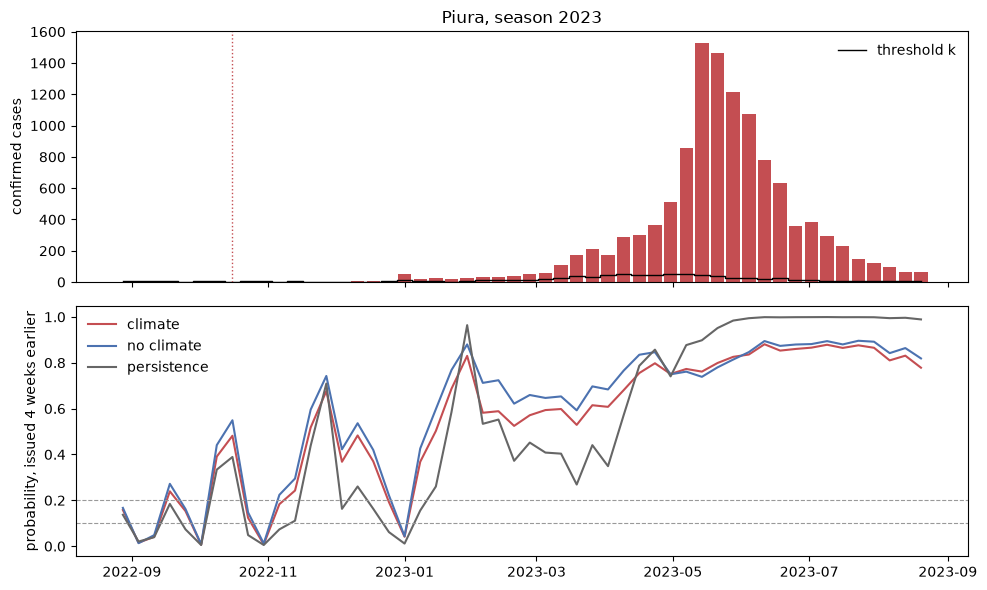

In [9]:
four = example[example.horizonte.eq(4)].sort_values("semana_inicio")
fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
top.bar(four.semana_inicio, four.casos_Dengue, width=6, color=np.where(four.brote.eq(1), "#C44E52", "0.7"))
top.step(four.semana_inicio, four.k, where="mid", color="black", lw=1, label="threshold k")
for d in four.semana_inicio[four.inicio]:
    top.axvline(d, color="#C44E52", ls=":", lw=1)
top.set_ylabel("confirmed cases")
top.set_title(f"{four.distrito.iloc[0]}, season 2023")
top.legend(frameon=False)
for name, color in (("climate", "#C44E52"), ("no climate", "#4C72B0"), ("persistence", "0.4")):
    bottom.plot(four.semana_inicio, four[name], color=color, label=name)
for t in oa.ALERT_THRESHOLDS:
    bottom.axhline(t, color="0.6", ls="--", lw=0.8)
bottom.set_ylabel("probability, issued 4 weeks earlier")
bottom.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "e11_ejemplo_distrito.png", dpi=150)

## Reading

- **Strata.** At four weeks, origins in quiet districts were 88.6% of district-weeks but held 23.1% of the elevated weeks (prevalence 2.0%, against 50.9% where the district was already active).
- **Climate by stratum.** Quiet: −1.12%, −1.46% and −1.17% at two to four weeks (intervals include zero; climate better in 13, 12 and 11 of 18 seasons). Active: +0.08%, +0.62% and +1.05% (intervals include zero).
- **Persistence by stratum.** Quiet: calibrated persistence had a lower Brier score than the no-climate model at two weeks (difference 6.37%, 0.84% to 13.41%) but a lower average precision (0.18 against 0.22). Active: both models had Brier scores 5–9% lower than persistence.
- **Onsets (527 weeks), fixed thresholds.** With alerts from any of the three horizons and threshold 0.1, alerts preceded 76.5% of onsets with climate, 77.0% without and 53.5% with persistence, at 7.1, 7.3 and 4.2 false alarms per district per 52 weeks under the same policy. Fixed thresholds compare forecasts at different false-alarm rates, so they are descriptive only.
- **Matched budgets.** At one to three false alarms per district per 52 weeks, the models detected 2 to 8 percentage points more onsets than calibrated persistence. The intervals excluded zero only at three false alarms with alerts four weeks ahead (climate model +5.3 points, 1.4 to 12.5) and at two with alerts from any horizon (+7.1, 1.5 to 11.1). No forecast detected more than 42% of onsets at these budgets.
- **Climate and onsets.** At matched budgets, climate changed detection by −1.3 to +0.8 points, with every interval including zero.
- **District example.** Piura district (the department capital) was elevated in 40 of the 52 weeks of the 2023 season. Its only onset under the definition was in October 2022, so the epidemic that began in January 2023 counts as continuation. Before the January surge, the three four-week forecasts were low (0.01–0.04 for the first week of January). Early in the epidemic (January–April) both models gave higher probabilities than persistence; once it was established (from May), persistence gave 0.88–1.00 and the models 0.74–0.90.